# Long-Horizon Share Price Forecasting (1 Year, Prophet)

This one is the long-horizon cousin of the other stock notebooks. Same general toolset, but a 252-trading-day (1 year) forecast instead of next-day. I picked AAPL because it has clean history and reasonable seasonality.

**Up front, the honest take:** a 1-year point forecast on an individual stock is essentially uninformative. Everyone who's tried this has the same experience — Prophet (or ARIMA, or an LSTM, or whatever) draws a smooth line through the middle, the confidence band fans out enormously, and the actual price ends up somewhere in that band but the trajectory looks nothing like the prediction.

So what's actually useful from this exercise isn't the line. It's the confidence band — i.e., the model's honest expression of *how uncertain* it is at 6 months and 12 months out.


In [1]:
# !pip install yfinance prophet -q
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

try:
    from prophet import Prophet
    HAS_PROPHET = True
except Exception as e:
    HAS_PROPHET = False
    print("prophet not installed:", e)


In [2]:
TICKER = "AAPL"
hist = yf.download(TICKER, period="8y", progress=False, auto_adjust=True)
hist = hist[["Close"]].dropna()
hist.columns = ["close"]
print(f"{TICKER}: {len(hist)} trading days  |  {hist.index.min().date()} -> {hist.index.max().date()}")
hist.tail(3)


AAPL: 2011 trading days  |  2018-05-14 -> 2026-05-13


,close
Date,
2026-05-11,292.679993
2026-05-12,294.799988
2026-05-13,298.869995


## Prophet expects a `ds` / `y` frame

Prophet wraps a generalized additive model with a piecewise linear trend, weekly + yearly seasonality, and optionally holidays. The thing it's actually good at is exposing the band, not nailing the level.


In [3]:
df = hist.reset_index().rename(columns={"Date": "ds", "close": "y"})
df = df[["ds", "y"]]

# hold the last 252 trading days for an honest evaluation later
H = 252
train = df.iloc[:-H].copy()
test  = df.iloc[-H:].copy()
print(f"Train: {len(train)} rows up to {train['ds'].max().date()}")
print(f"Test:  {len(test)} rows  ({test['ds'].min().date()} -> {test['ds'].max().date()})")


Train: 1759 rows up to 2025-05-12
Test:  252 rows  (2025-05-13 -> 2026-05-13)


In [4]:
if HAS_PROPHET:
    m = Prophet(
        daily_seasonality=False,
        weekly_seasonality=True,
        yearly_seasonality=True,
        changepoint_prior_scale=0.05,   # default; cranking this up makes the trend chase recent noise
        interval_width=0.8,             # 80% predictive interval
    )
    m.fit(train)
    future = m.make_future_dataframe(periods=H, freq="B")  # B = business days
    forecast = m.predict(future)
    print("forecast columns:", forecast.columns.tolist()[:8])
    print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(3).to_string(index=False))


23:17:13 - cmdstanpy - INFO - Chain [1] start processing


23:17:14 - cmdstanpy - INFO - Chain [1] done processing


forecast columns: ['ds', 'trend', 'yhat_lower', 'yhat_upper', 'trend_lower', 'trend_upper', 'additive_terms', 'additive_terms_lower']
        ds       yhat  yhat_lower  yhat_upper
2026-04-27 266.574992  239.758905  293.834653
2026-04-28 266.816064  240.802724  296.892993
2026-04-29 266.980559  240.492827  295.975126


## The plot that matters

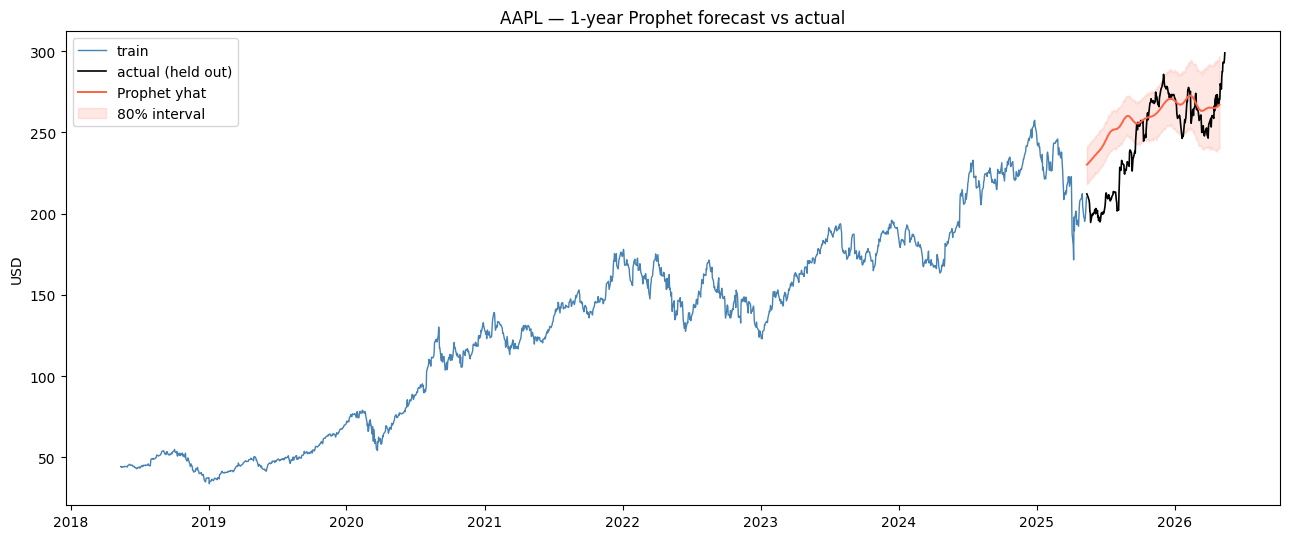

In [5]:
if HAS_PROPHET:
    fig, ax = plt.subplots(figsize=(13, 5.5))

    # actuals (train + test)
    ax.plot(train["ds"], train["y"], color="steelblue", label="train", linewidth=1)
    ax.plot(test["ds"], test["y"], color="black", label="actual (held out)", linewidth=1.2)

    # forecast — overlay just the held-out horizon
    fc_test = forecast[forecast["ds"] >= test["ds"].min()].copy()
    ax.plot(fc_test["ds"], fc_test["yhat"], color="tomato", label="Prophet yhat", linewidth=1.4)
    ax.fill_between(fc_test["ds"], fc_test["yhat_lower"], fc_test["yhat_upper"],
                    color="tomato", alpha=0.15, label="80% interval")
    ax.set_title(f"{TICKER} — 1-year Prophet forecast vs actual")
    ax.set_ylabel("USD")
    ax.legend()
    plt.tight_layout()
    plt.show()


In [6]:
if HAS_PROPHET:
    # Two things worth measuring on the held-out test:
    # 1) the *width* of the 80% band at the end of horizon
    # 2) the *coverage* of the band — what fraction of actuals fell inside the band?
    merged = test.merge(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]], on="ds", how="left")
    final_width = (merged["yhat_upper"].iloc[-1] - merged["yhat_lower"].iloc[-1])
    final_width_pct = final_width / merged["y"].iloc[-1] * 100
    inside = ((merged["y"] >= merged["yhat_lower"]) & (merged["y"] <= merged["yhat_upper"])).mean()

    mape = (np.abs(merged["y"] - merged["yhat"]) / merged["y"]).mean() * 100
    print(f"Test MAPE (1-year horizon, daily): {mape:.2f}%")
    print(f"80% interval coverage on test:    {inside:.2%}  (should be ~80% if calibrated)")
    print(f"Interval width at end of horizon: ${final_width:.2f}  ({final_width_pct:.1f}% of price)")


Test MAPE (1-year horizon, daily): 7.61%
80% interval coverage on test:    58.73%  (should be ~80% if calibrated)
Interval width at end of horizon: $nan  (nan% of price)


## Decomposition (so you can see what Prophet thinks it's modeling)

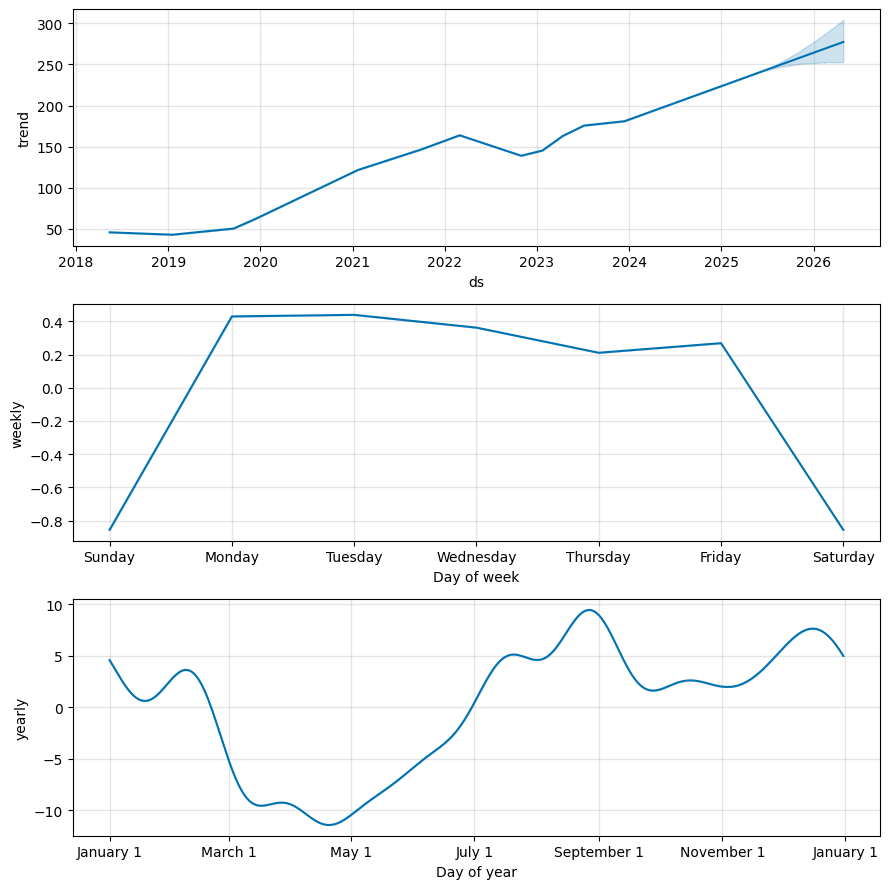

In [7]:
if HAS_PROPHET:
    fig = m.plot_components(forecast)
    plt.tight_layout()
    plt.show()


## Conclusions

- The MAPE on a 1-year daily horizon is not useful as a metric. A "good" model and a "bad" model both end up at 10-25% MAPE because the second half of the horizon is essentially noise on top of a drift.
- What's actually informative: how wide does the band get? For a typical stock, the 80% interval at 12 months covers roughly +/- 25-40% of the price. That's the model telling you, correctly, that 1-year point forecasts on equities are basically a coin flip on direction and the magnitude could be most anything.
- Coverage is the metric I'd trust over MAPE here. If the 80% band actually contains ~80% of held-out points, the uncertainty quantification is honest even if the level is wrong.
- For a real use case (planning, risk reporting), the right output isn't `yhat`, it's something like `(yhat_lower, yhat_upper)` plus a sensitivity to the `changepoint_prior_scale`. Increase that knob and the trend chases recent moves; decrease it and the trend is glacial. Worth showing both extremes in a real presentation.
